# ML-02, ML-03 & ML-04 · Baseline, Fine-tune IndoBERT, dan Evaluasi

**Proyek:** HoaxScan, bagian Machine Learning
**Input:** `train.csv` dan `test.csv` hasil ML-01 (`processed_data.zip`)
**Data:** berita fakta (CNN, Kompas, Tempo) dan narasi hoaks (Turnbackhoax).

| Task | Isi | Bagian |
|---|---|---|
| **ML-02** | Baseline TF-IDF + Logistic Regression sebagai pembanding | 4 |
| **ML-03** | Fine-tune `indobert-base-p1` untuk klasifikasi biner (model utama) | 5 |
| **ML-04** | Evaluasi holdout di data test: F1 per kelas dan confusion matrix | 7 |

Digabung dalam satu notebook supaya kedua model **memakai data dan pengaturan yang sama persis**:

| Pengaturan | ML-02 (baseline) | ML-03 (IndoBERT) |
|---|---|---|
| Data | train/val 90/10, seed 42 | sama |
| Panjang input | 256 token pertama (tokenizer IndoBERT) | 256 token |
| Penyeimbang kelas | class weight balanced | sama |
| Pemilihan model | `C` terbaik dari 3 kandidat, berdasarkan F1 val | epoch terbaik dari 3, berdasarkan F1 val |
| Metrik | accuracy, precision, recall, F1 (macro) | sama |

**Penting:**
- Jalankan di **Google Colab dengan GPU**: *Runtime → Change runtime type → T4 GPU*.
- `test.csv` **baru dibuka di bagian 7**, setelah semua pilihan (nilai `C` dan epoch) selesai. Setelah melihat skor test, **jangan mengubah pengaturan lalu melatih ulang**, karena skor test jadi tidak jujur.

## 1. Ambil data hasil ML-01
Notebook mencari `data/processed/train.csv`. Bila belum ada, ia membuka `processed_data.zip`. Di Colab, bila zip juga belum ada, akan muncul tombol **Choose Files** untuk meng-upload `processed_data.zip`.

In [ ]:
import os, sys, zipfile
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
DATA_DIR = os.path.join("data", "processed")
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
ID2LABEL = {0: "fakta", 1: "hoax"}

train_path = os.path.join(DATA_DIR, "train.csv")
if not os.path.exists(train_path):
    if not os.path.exists("processed_data.zip"):
        if IN_COLAB:
            from google.colab import files
            print("Upload processed_data.zip hasil ML-01:")
            files.upload()
        else:
            raise FileNotFoundError("processed_data.zip tidak ditemukan. Jalankan ML_preprocessing.ipynb dulu.")
    with zipfile.ZipFile("processed_data.zip") as z:
        z.extractall(DATA_DIR)

full_train = pd.read_csv(train_path)
print("train.csv:", full_train.shape)
print(full_train["label"].value_counts().rename(index=ID2LABEL))

Upload processed_data.zip hasil ML-01:


Saving processed_data.zip to processed_data.zip
train.csv: (21752, 3)
label
fakta    16755
hoax      4997
Name: count, dtype: int64


## 2. Bagi train → train + val (90 / 10)
Data validasi dipakai untuk **memilih versi terbaik** tiap model (nilai `C` untuk baseline, epoch untuk IndoBERT). Model tidak belajar dari data ini.

Kedua bagian disimpan ke CSV supaya **ML-06 (threshold) memakai pembagian yang sama persis**.

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42
train_df, val_df = train_test_split(full_train, test_size=0.10,
                                    stratify=full_train["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

train_df.to_csv(os.path.join(OUTPUT_DIR, "train_split.csv"), index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR, "val_split.csv"), index=False)

pd.DataFrame({
    "Jumlah": [len(train_df), len(val_df)],
    "Hoax": [int(train_df.label.sum()), int(val_df.label.sum())],
    "Fakta": [int((train_df.label == 0).sum()), int((val_df.label == 0).sum())],
}, index=["train", "val"])

,Jumlah,Hoax,Fakta
train,19576,4497,15079
val,2176,500,1676


## 3. Pengaturan bersama
Dipakai oleh **kedua model**:
- **Tokenizer IndoBERT** dan batas **256 token**. Baseline memakainya untuk memotong teks, IndoBERT untuk membaca teks.
- **Class weight**: data berisi ±77% fakta dan ±23% hoaks. Kesalahan pada kelas hoaks (yang sedikit) dihitung lebih berat supaya model tidak "malas" menebak fakta terus.
- **Fungsi metrik**: accuracy, precision, recall, dan F1. Precision, recall, dan F1 dihitung **macro** (rata-rata kelas fakta dan hoax).

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, set_seed
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

MODEL_NAME = "indobenchmark/indobert-base-p1"
MAX_LENGTH = 256  # IndoBERT maks 512; 256 cukup untuk judul + paragraf awal dan jauh lebih cepat

set_seed(SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# rumus sama dengan class_weight="balanced" di Logistic Regression
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"])
print(f"Class weight -> fakta: {weights[0]:.2f} | hoax: {weights[1]:.2f}")

METRICS = ["accuracy", "precision", "recall", "f1"]

def scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro"),
        "f1": f1_score(y_true, y_pred, average="macro"),
    }

BASE_C, BERT_C = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["fakta", "hoax"]); ax.set_yticks([0, 1], ["fakta", "hoax"])
    ax.set_xlabel("Prediksi model", color=MUTED); ax.set_ylabel("Label sebenarnya", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color=INK)
    plt.tight_layout(); plt.show()

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Class weight -> fakta: 0.65 | hoax: 2.18


## 4. ML-02 · Baseline TF-IDF + Logistic Regression
Model sederhana sebagai **patokan** untuk IndoBERT:
1. Apakah IndoBERT jauh lebih baik sehingga sepadan dengan biayanya (GPU, ±400 MB)?
2. Apakah data terlalu mudah (bisa dibedakan hanya dari pola kata)?
3. Kata apa yang dipakai model untuk memutuskan (cek *bias dataset*)?

### 4.1 Potong teks di 256 token pertama
IndoBERT hanya membaca **256 token pertama** tiap teks. Supaya baseline melihat **potongan teks yang sama persis**, teks dipotong memakai tokenizer IndoBERT, lalu dikembalikan menjadi kalimat. Tanpa langkah ini, TF-IDF membaca seluruh artikel dan mendapat informasi lebih banyak dari IndoBERT.

In [ ]:
def truncate(texts):
    ids = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)["input_ids"]
    return tokenizer.batch_decode(ids, skip_special_tokens=True)

train_df["text_256"] = truncate(train_df["text"])
val_df["text_256"] = truncate(val_df["text"])

ex = train_df.loc[train_df["label"] == 0].iloc[0]
print("Contoh asli  :", ex["text"][:300], "...")
print("Contoh dipakai:", ex["text_256"][:300], "...")

Contoh asli  : Dituding Mark-up Dana Reses, Viani Akan Tuntut PSI Rp1 T Anggota Komisi D DPRD DKI Jakarta Viani Limardi akan menuntut partai Solidaritas Indonesia (PSI) atas tudingan penggelembungan alias mark-up dana reses yang berbuntut pemecatan dirinya sebagai anggota partai.Selama ini, dirinya tak pernah dibe ...
Contoh dipakai: dituding mark - up dana reses, viani akan tuntut psi rp1 t anggota komisi d dprd dki jakarta viani limardi akan menuntut partai solidaritas indonesia ( psi ) atas tudingan penggelembungan alias mark - up dana reses yang berbuntut pemecatan dirinya sebagai anggota partai. selama ini, dirinya tak pern ...


### 4.2 Latih model dan pilih `C` terbaik
- **TF-IDF** mengubah teks menjadi angka: kata yang sering muncul di satu teks tetapi jarang di teks lain diberi nilai tinggi. Dipakai kata tunggal dan pasangan dua kata (*bigram*).
- **Logistic Regression** belajar menebak hoax/fakta dari angka-angka tersebut, dengan `class_weight="balanced"`.
- **`C`** mengatur seberapa ketat model menyesuaikan diri dengan data train (kecil = lebih sederhana, besar = lebih detail). Dicoba **3 nilai**, lalu dipilih yang **F1 val**-nya tertinggi, setara IndoBERT memilih epoch terbaik dari 3 epoch.

TF-IDF dan LR digabung dalam satu `Pipeline`, sehingga model yang disimpan bisa langsung menerima teks.

In [ ]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

TFIDF_PARAMS = dict(max_features=10_000, ngram_range=(1, 2), sublinear_tf=True, min_df=2)
C_CANDIDATES = [0.1, 1.0, 10.0]

rows, candidates = [], {}
start = time.time()
for C in C_CANDIDATES:
    m = Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("lr", LogisticRegression(C=C, class_weight="balanced", max_iter=1000, random_state=SEED)),
    ])
    m.fit(train_df["text_256"], train_df["label"])
    candidates[C] = m
    rows.append({"C": C, **scores(val_df["label"], m.predict(val_df["text_256"]))})

c_search = pd.DataFrame(rows).set_index("C")
BEST_C = c_search["f1"].idxmax()
baseline = candidates[BEST_C]
print(f"Selesai dalam {time.time() - start:.1f} detik | C terbaik: {BEST_C}")
c_search.round(4)

Selesai dalam 26.4 detik | C terbaik: 10.0


,accuracy,precision,recall,f1
C,,,,
0.1,0.9568,0.9250,0.9621,0.9416
1.0,0.9747,0.9559,0.9752,0.9650
10.0,0.9821,0.9702,0.9799,0.9749


### 4.3 Evaluasi baseline di data val
Ini **bukan** nilai akhir untuk laporan. Nilai akhir diambil dari data test di bagian 7 (ML-04).

              precision    recall  f1-score   support

       fakta      0.993     0.984     0.988      1676
        hoax      0.948     0.976     0.962       500

    accuracy                          0.982      2176
   macro avg      0.970     0.980     0.975      2176
weighted avg      0.982     0.982     0.982      2176



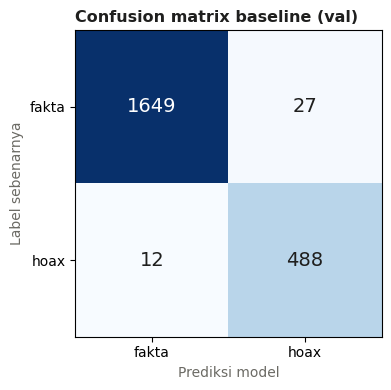

In [ ]:
bl_probs = baseline.predict_proba(val_df["text_256"])
bl_pred = bl_probs.argmax(axis=1)

print(classification_report(val_df["label"], bl_pred, target_names=["fakta", "hoax"], digits=3))
plot_cm(val_df["label"], bl_pred, "Confusion matrix baseline (val)")

### 4.4 Kata yang paling memengaruhi keputusan baseline
Bobot positif mendorong ke **hoax**, bobot negatif ke **fakta**. Gunanya untuk mengecek apakah model belajar **isi berita** atau hanya **gaya tulisan / ciri sumber** (misalnya nama kota di awal berita media besar). Ini terkait limitasi *bias dataset* di laporan.

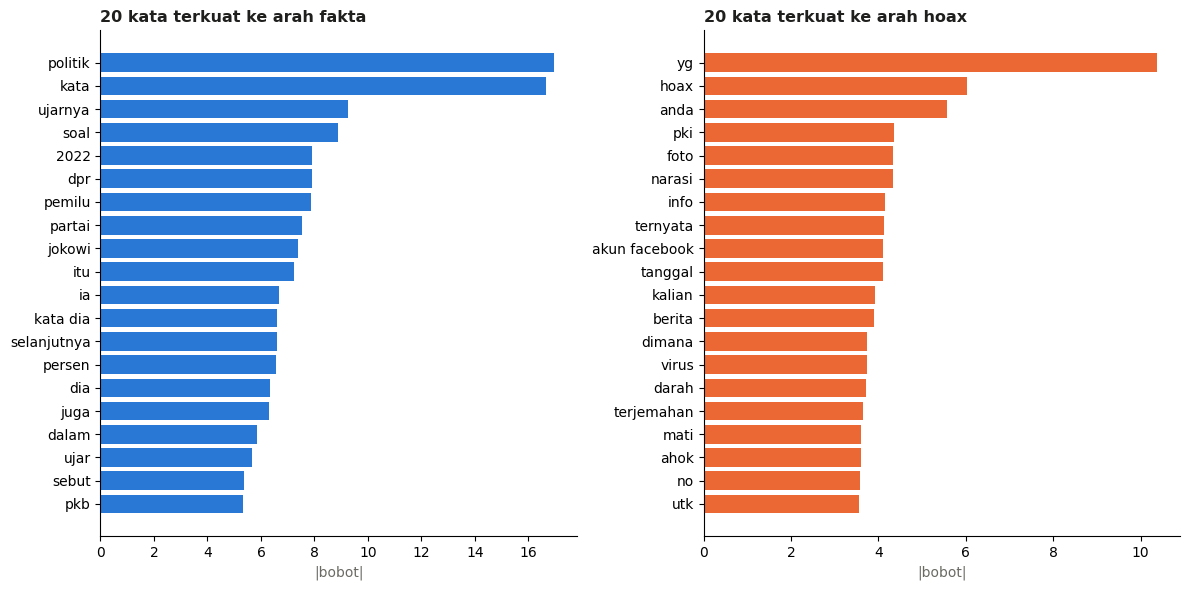

In [ ]:
vocab = np.array(baseline.named_steps["tfidf"].get_feature_names_out())
coef = baseline.named_steps["lr"].coef_[0]
order = np.argsort(coef)
top_fakta, top_hoax = order[:20], order[-20:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, idx, color, title in [(axes[0], top_fakta, BASE_C, "20 kata terkuat ke arah fakta"),
                              (axes[1], top_hoax, BERT_C, "20 kata terkuat ke arah hoax")]:
    ax.barh(vocab[idx][::-1], np.abs(coef[idx])[::-1], color=color)
    ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color=INK)
    ax.set_xlabel("|bobot|", color=MUTED)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 5. ML-03 · Fine-tune IndoBERT
### 5.1 Tokenisasi
Tokenizer mengubah teks menjadi potongan kata (token) berbentuk angka yang dimengerti IndoBERT. Panjang tiap batch disamakan otomatis saat training (*dynamic padding*), sehingga lebih cepat.

In [ ]:
from transformers import DataCollatorWithPadding

class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tokenizer(df["text"].tolist(), truncation=True, max_length=MAX_LENGTH)
        self.labels = df["label"].tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

train_ds, val_ds = NewsDataset(train_df), NewsDataset(val_df)
collator = DataCollatorWithPadding(tokenizer)

lengths = pd.DataFrame({
    "token": [len(x) for x in train_ds.enc["input_ids"]],
    "label": train_df["label"].map(ID2LABEL),
})
print(f"Batas panjang input: {MAX_LENGTH} token")
print("Median panjang token per label:", lengths.groupby("label")["token"].median().to_dict())
print("Teks yang terpotong (%):", (lengths["token"] >= MAX_LENGTH).groupby(lengths["label"]).mean().mul(100).round(1).to_dict())
print("Contoh token:", tokenizer.convert_ids_to_tokens(train_ds.enc["input_ids"][0])[:20])

Batas panjang input: 256 token
Median panjang token per label: {'fakta': 256.0, 'hoax': 43.0}
Teks yang terpotong (%): {'fakta': 61.3, 'hoax': 5.0}
Contoh token: ['[CLS]', 'ditu', '##ding', 'mark', '-', 'up', 'dana', 'res', '##es', ',', 'via', '##ni', 'akan', 'tuntut', 'psi', 'rp', '##1', 't', 'anggota', 'komisi']


### 5.2 Siapkan model dan training
- Pesan `classifier.bias | MISSING` dan `classifier.weight | MISSING` saat model dimuat itu **normal**: lapisan penentu label hoax/fakta masih baru dan akan dilatih di sini.
- Training **3 epoch**. Di akhir, otomatis memakai **epoch terbaik** berdasarkan **F1 val**, bukan epoch terakhir.

In [ ]:
import math
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

CLASS_WEIGHTS = torch.tensor(weights, dtype=torch.float)
CKPT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id={v: k for k, v in ID2LABEL.items()})

class WeightedTrainer(Trainer):
    # Trainer biasa + loss yang memakai class weight
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return scores(labels, np.argmax(logits, axis=-1))

EPOCHS, BATCH_SIZE = 3, 16
# warmup 10% dari total langkah training; ditulis sebagai jumlah langkah (int)
# karena transformers versi baru tidak lagi menerima warmup_ratio
total_steps = math.ceil(len(train_ds) / BATCH_SIZE) * EPOCHS
WARMUP_STEPS = int(0.1 * total_steps)

args = TrainingArguments(
    output_dir=CKPT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=WARMUP_STEPS,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    save_only_model=True,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### 5.3 Training
Butuh GPU. Dengan T4, perkiraan ±5 menit per epoch (belum diuji; lihat progress bar).

In [ ]:
start = time.time()
train_result = trainer.train()
print(f"\nSelesai dalam {(time.time() - start) / 60:.1f} menit")
print("Epoch terbaik (checkpoint):", trainer.state.best_model_checkpoint)
print(f"F1 val terbaik: {trainer.state.best_metric:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.119737,0.097780,0.990349,0.993061,0.979702,0.986182
2,0.024639,0.062360,0.992188,0.987968,0.990017,0.988987
3,0.004326,0.067761,0.994485,0.994288,0.990105,0.992177


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Selesai dalam 13.6 menit
Epoch terbaik (checkpoint): outputs/checkpoints/checkpoint-3672
F1 val terbaik: 0.9922


### 5.4 Riwayat training per epoch
- **Loss**: semakin kecil semakin baik. Bila loss train terus turun tetapi loss val naik, model mulai menghafal (*overfitting*).
- **F1 val**: dipakai untuk memilih epoch terbaik.

In [ ]:
hist = pd.DataFrame(trainer.state.log_history)
train_loss = hist.dropna(subset=["loss"])[["epoch", "loss"]] if "loss" in hist else pd.DataFrame()
eval_rows = hist.dropna(subset=["eval_loss"])
history = eval_rows[["epoch", "eval_loss"] + [f"eval_{m}" for m in METRICS]].merge(train_loss, on="epoch", how="left")
history = history.rename(columns={"loss": "train_loss", "eval_loss": "val_loss",
                                  **{f"eval_{m}": f"val_{m}" for m in METRICS}})
history["epoch"] = history["epoch"].round().astype(int)
history = history[["epoch", "train_loss", "val_loss"] + [f"val_{m}" for m in METRICS]]
history.to_csv(os.path.join(OUTPUT_DIR, "training_history.csv"), index=False)
history.round(4)

,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1
0,1,0.1197,0.0978,0.9903,0.9931,0.9797,0.9862
1,2,0.0246,0.0624,0.9922,0.9880,0.9900,0.9890
2,3,0.0043,0.0678,0.9945,0.9943,0.9901,0.9922


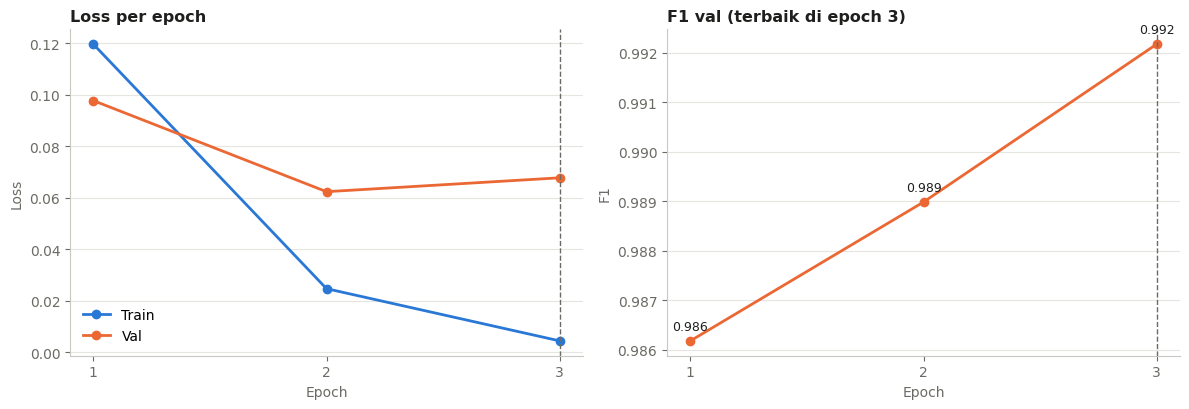

In [ ]:
best_epoch = int(history.loc[history["val_f1"].idxmax(), "epoch"])

def style(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color=INK)
    ax.set_xlabel("Epoch", color=MUTED); ax.set_ylabel(ylabel, color=MUTED)
    ax.set_xticks(history["epoch"])
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]: ax.spines[s].set_color("#c9c8c2")
    ax.tick_params(colors=MUTED)
    ax.axvline(best_epoch, color=MUTED, linestyle="--", linewidth=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(history["epoch"], history["train_loss"], marker="o", color=BASE_C, linewidth=2, label="Train")
ax1.plot(history["epoch"], history["val_loss"], marker="o", color=BERT_C, linewidth=2, label="Val")
ax1.legend(frameon=False)
style(ax1, "Loss per epoch", "Loss")

ax2.plot(history["epoch"], history["val_f1"], marker="o", color=BERT_C, linewidth=2)
for e, v in zip(history["epoch"], history["val_f1"]):
    ax2.annotate(f"{v:.3f}", (e, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=INK)
style(ax2, f"F1 val (terbaik di epoch {best_epoch})", "F1")
plt.tight_layout(); plt.show()

### 5.5 Evaluasi IndoBERT di data val
Ini **bukan** nilai akhir untuk laporan. Nilai akhir diambil dari data test di bagian 7 (ML-04).

              precision    recall  f1-score   support

       fakta      0.995     0.998     0.996      1676
        hoax      0.994     0.982     0.988       500

    accuracy                          0.994      2176
   macro avg      0.994     0.990     0.992      2176
weighted avg      0.994     0.994     0.994      2176



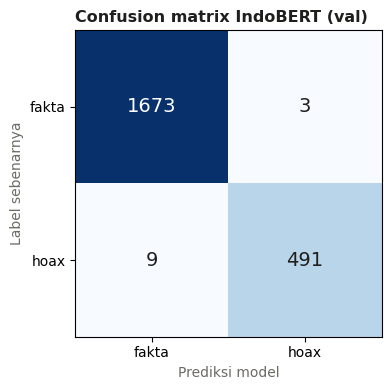

In [ ]:
pred = trainer.predict(val_ds)
bert_probs = torch.softmax(torch.tensor(pred.predictions), dim=-1).numpy()
bert_pred = bert_probs.argmax(axis=1)

print(classification_report(val_df["label"], bert_pred, target_names=["fakta", "hoax"], digits=3))
plot_cm(val_df["label"], bert_pred, "Confusion matrix IndoBERT (val)")

## 6. Perbandingan ML-02 vs ML-03 (data val)
Kedua model dinilai pada **data val yang sama** dengan ambang default 0,5. Selain 4 metrik macro, ditampilkan juga **F1 per kelas** karena kelas hoax yang paling penting.

Perbandingan resmi untuk laporan ada di **bagian 7 (ML-04)** dengan data test.

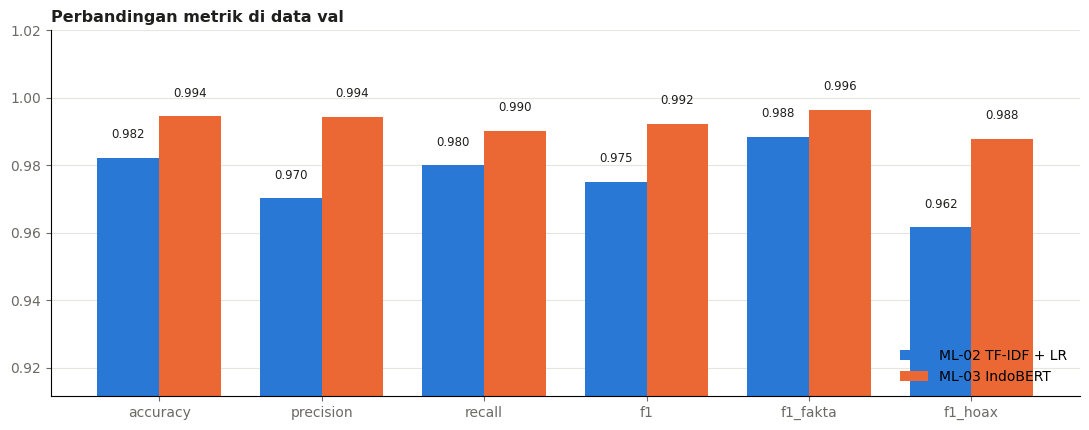

,accuracy,precision,recall,f1,f1_fakta,f1_hoax,selisih_f1
ML-02 TF-IDF + LR,0.9821,0.9702,0.9799,0.9749,0.9883,0.9616,0.0000
ML-03 IndoBERT,0.9945,0.9943,0.9901,0.9922,0.9964,0.9879,0.0172


In [ ]:
BASE_NAME, BERT_NAME = "ML-02 TF-IDF + LR", "ML-03 IndoBERT"
COMPARE_COLS = METRICS + ["f1_fakta", "f1_hoax"]

def compare(y_true, preds):
    rows = {}
    for name, y_pred in preds.items():
        per_class = f1_score(y_true, y_pred, average=None)
        rows[name] = {**scores(y_true, y_pred), "f1_fakta": per_class[0], "f1_hoax": per_class[1]}
    table = pd.DataFrame(rows).T
    table["selisih_f1"] = table["f1"] - table.loc[BASE_NAME, "f1"]
    return table

def plot_compare(table, title):
    x = np.arange(len(COMPARE_COLS)); w = 0.38
    fig, ax = plt.subplots(figsize=(11, 4.4))
    for i, (name, color) in enumerate([(BASE_NAME, BASE_C), (BERT_NAME, BERT_C)]):
        vals = table.loc[name, COMPARE_COLS].values
        bars = ax.bar(x + (i - 0.5) * w, vals, w, label=name, color=color)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=8.5, color=INK)
    ax.set_xticks(x, COMPARE_COLS)
    ax.set_ylim(max(0, table[COMPARE_COLS].values.min() - 0.05), 1.02)
    ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color=INK)
    ax.legend(frameon=False, loc="lower right")
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED)
    plt.tight_layout(); plt.show()

comparison = compare(val_df["label"], {BASE_NAME: bl_pred, BERT_NAME: bert_pred})
comparison.to_csv(os.path.join(OUTPUT_DIR, "comparison_val.csv"))
plot_compare(comparison, "Perbandingan metrik di data val")
comparison.round(4)

## 7. ML-04 · Evaluasi akhir di data test (holdout)
`test.csv` (20% data, 5.439 baris) **belum pernah dilihat** kedua model, baik saat training maupun saat memilih `C` dan epoch. Skor di bagian ini adalah **nilai resmi untuk laporan**.

Perlakuan sama untuk kedua model: teks dipotong 256 token, ambang default 0,5.

### 7.1 Prediksi kedua model

In [ ]:
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
print("test.csv:", test_df.shape)
print(test_df["label"].value_counts().rename(index=ID2LABEL))

# ML-02: potong 256 token, sama dengan bagian 4.1
test_df["text_256"] = truncate(test_df["text"])
bl_test_probs = baseline.predict_proba(test_df["text_256"])
bl_test_pred = bl_test_probs.argmax(axis=1)

# ML-03: model IndoBERT dari epoch terbaik
bert_test = trainer.predict(NewsDataset(test_df))
bert_test_probs = torch.softmax(torch.tensor(bert_test.predictions), dim=-1).numpy()
bert_test_pred = bert_test_probs.argmax(axis=1)

for name, y_pred in [(BASE_NAME, bl_test_pred), (BERT_NAME, bert_test_pred)]:
    print(f"\n=== {name} (test) ===")
    print(classification_report(test_df["label"], y_pred, target_names=["fakta", "hoax"], digits=3))

test.csv: (5439, 3)
label
fakta    4190
hoax     1249
Name: count, dtype: int64



=== ML-02 TF-IDF + LR (test) ===
              precision    recall  f1-score   support

       fakta      0.992     0.979     0.986      4190
        hoax      0.934     0.974     0.953      1249

    accuracy                          0.978      5439
   macro avg      0.963     0.977     0.970      5439
weighted avg      0.979     0.978     0.978      5439


=== ML-03 IndoBERT (test) ===
              precision    recall  f1-score   support

       fakta      0.996     0.998     0.997      4190
        hoax      0.992     0.986     0.989      1249

    accuracy                          0.995      5439
   macro avg      0.994     0.992     0.993      5439
weighted avg      0.995     0.995     0.995      5439



### 7.2 Confusion matrix
- **Kiri atas**: fakta yang benar ditebak fakta. **Kanan bawah**: hoax yang benar ditebak hoax.
- **Kiri bawah**: hoax yang lolos ditebak fakta (*false negative*), kesalahan paling berbahaya.
- **Kanan atas**: fakta yang salah ditandai hoax (*false positive*).

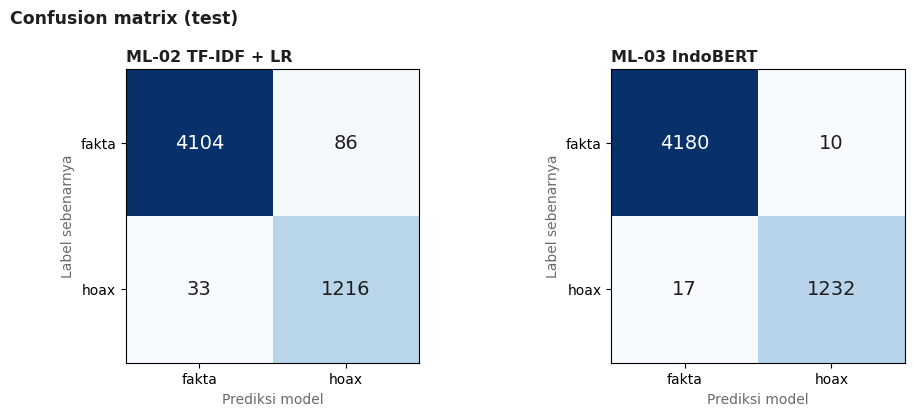

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, y_pred) in zip(axes, [(BASE_NAME, bl_test_pred), (BERT_NAME, bert_test_pred)]):
    cm = confusion_matrix(test_df["label"], y_pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["fakta", "hoax"]); ax.set_yticks([0, 1], ["fakta", "hoax"])
    ax.set_xlabel("Prediksi model", color=MUTED); ax.set_ylabel("Label sebenarnya", color=MUTED)
    ax.set_title(name, loc="left", fontsize=11.5, fontweight="bold", color=INK)
plt.suptitle("Confusion matrix (test)", x=0.02, ha="left", fontsize=12.5, fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

### 7.3 Perbandingan akhir (untuk laporan)

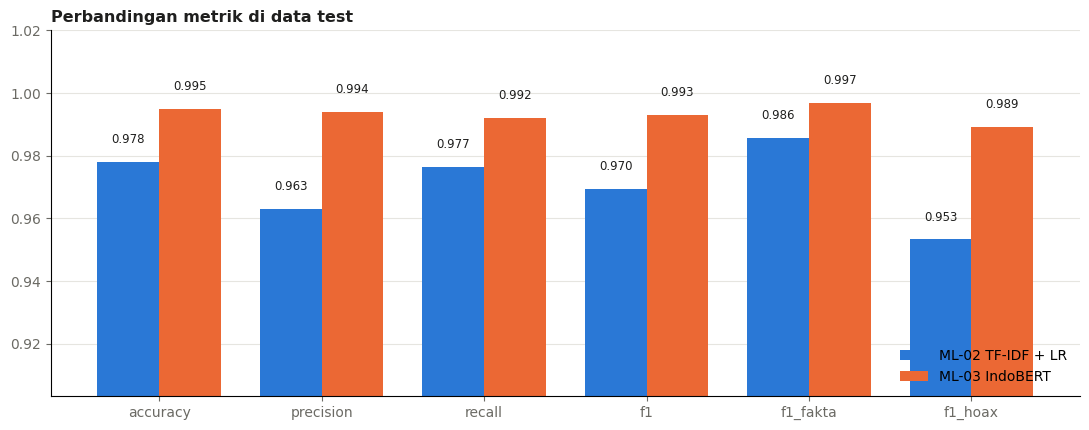

,accuracy,precision,recall,f1,f1_fakta,f1_hoax,selisih_f1
ML-02 TF-IDF + LR,0.9781,0.9630,0.9765,0.9695,0.9857,0.9534,0.0000
ML-03 IndoBERT,0.9950,0.9939,0.9920,0.9930,0.9968,0.9892,0.0234


In [ ]:
comparison_test = compare(test_df["label"], {BASE_NAME: bl_test_pred, BERT_NAME: bert_test_pred})
comparison_test.to_csv(os.path.join(OUTPUT_DIR, "comparison_test.csv"))
plot_compare(comparison_test, "Perbandingan metrik di data test")
comparison_test.round(4)

### 7.4 Contoh kesalahan IndoBERT
Teks yang salah ditebak dengan keyakinan paling tinggi. Berguna untuk bagian analisis di laporan: apakah kesalahan karena topik, gaya tulisan, atau label yang meragukan.

In [ ]:
test_out = test_df[["text", "label", "sumber"]].copy()
test_out["prob_hoax_baseline"] = bl_test_probs[:, 1].round(6)
test_out["pred_baseline"] = bl_test_pred
test_out["prob_hoax_indobert"] = bert_test_probs[:, 1].round(6)
test_out["pred_indobert"] = bert_test_pred
test_out.to_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv"), index=False)

fn = test_out[(test_out.label == 1) & (test_out.pred_indobert == 0)].nsmallest(5, "prob_hoax_indobert")
fp = test_out[(test_out.label == 0) & (test_out.pred_indobert == 1)].nlargest(5, "prob_hoax_indobert")
pd.set_option("display.max_colwidth", 200)
print(f"Hoax lolos (false negative): {int(((test_out.label == 1) & (test_out.pred_indobert == 0)).sum())} teks")
display(fn[["text", "sumber", "prob_hoax_indobert"]])
print(f"Fakta ditandai hoax (false positive): {int(((test_out.label == 0) & (test_out.pred_indobert == 1)).sum())} teks")
display(fp[["text", "sumber", "prob_hoax_indobert"]])

Hoax lolos (false negative): 17 teks


,text,sumber,prob_hoax_indobert
4820,KSP: Jokowi Terima dan Dengar Aspirasi Rakyat Soal Demo BBM Jokowi menerima aspirasi masyarakat yang telah menggelar aksi unjuk rasa soal kenaikan harga BBM dalam dua minggu terakhir. Jokowi mende...,Turnbackhoax,0.000030
2134,"Ketua Baznas: Kalau Infaq Masih Dikategorikan Pungli, Langkahi Mayatku Satu lagi kontroversi muncul di negeri ini. Dalam rilisnya baru-baru ini, Satgas Sapu Bersih Pungutan Liar (Saber Pungli) mem...",Turnbackhoax,0.000058
3905,"Yang bertandangan di bawah ini ketua partai, Pimpinan Partai Politik Tingkat Pusat Partai Demokrasi Indonesia Perjuangan. Berdasarkan usulan Pimpinan Partai Politik Jawa Timur memberikan persetuju...",Turnbackhoax,0.000119
4020,Ma’ruf Amin Sebut Uang Haji Dipakai Dulu untuk IKN Haji Dipakai Dulu untuk IKN dan Infrastruktur Caption Oak ini kata Cebong.,Turnbackhoax,0.000154
2198,Berikut Susunan Kabinet II Jokowi-Amin yang baru saja NgafeBisnis terima : KOMPOSISI IDEAL KABINET KERJA JILID II PERIODE 2019-2024 Presiden RI: Ir. H. Joko Widodo Wakil Presiden RI: Prof. Dr (HC)...,Turnbackhoax,0.000249


Fakta ditandai hoax (false positive): 10 teks


,text,sumber,prob_hoax_indobert
4034,September 1965 dan Kisah Orang-orang Buangan... adik Pramoedya yang lain seperti Prawito Toer dan Koesalah Soebagyo Toer juga dijebloskan ke penjara karena dituding antek komunis. Hanya Soesetyo T...,Kompas,0.999977
5261,"Video Lautan Manusia pada Pelepasan Jabatan Anies Baswedan 3 Yamaha RX-King Indonesia di Yogyakarta. Video yang diklaim sebagai lautan manusia pada pelepasan jabatan Anies Baswedan, disebarkan ole...",Kompas,0.999973
1324,"Top Nasional: Daftar 91 Obat Sirup yang Diduga Sebabkan Gagal Ginjal Akut, Buku Hitam Ferdy Sambo ped27. Elkana Syrup28. Eritromisin29. Etamox syrup30. Fartolin Syrup31. Ferro K32. Hecosan33. Hufa...",Tempo,0.999950
4755,"Jelang G20, Luhut: Pasti Ada Banyak Orang yang Minta Tolong ke Jokowi negara yang kita lihat super besar itu, minta tolongnya ke Jokowi. Mereka ngirim utusannya ke saya, ‘gini, gini’, kata dia.",Tempo,0.999783
4008,"Lebanon Diyakini Tidak akan Terima Bantuan dari Israel, Ini Sebabnya Pasca-ledakan dahsyat yang menghantam Beirut, Lebanon, pada Selasa (4/8/2020), banyak negara yang berbondong-bondong segera men...",Kompas,0.999456


## 8. Simpan model dan hasil
| File | Isi | Dipakai di |
|---|---|---|
| `indobert-hoax-v1/` | model IndoBERT, tokenizer, `training_config.json` (skor val dan test) | ML-06, ML-07 |
| `baseline/` | model baseline (input harus dipotong 256 token seperti bagian 4.1) dan `baseline_config.json` | arsip pembanding |
| `val_predictions.csv` | `prob_hoax` IndoBERT di data val | ML-06 (ambang 0,85) |
| `val_predictions_baseline.csv` | `prob_hoax` baseline di data val | arsip |
| `test_predictions.csv` | prediksi kedua model di data test | laporan, analisis kesalahan |
| `comparison_val.csv`, `comparison_test.csv`, `training_history.csv` | tabel perbandingan dan riwayat epoch | laporan |

In [ ]:
import json, shutil, joblib

def save_val_predictions(probs, preds, filename):
    out = val_df[["text", "label"]].copy()
    out["prob_hoax"] = probs[:, 1].round(6)
    out["pred"] = preds
    out.to_csv(os.path.join(OUTPUT_DIR, filename), index=False)

# ML-02
BASE_DIR = os.path.join(OUTPUT_DIR, "baseline")
os.makedirs(BASE_DIR, exist_ok=True)
joblib.dump(baseline, os.path.join(BASE_DIR, "baseline_tfidf_lr.joblib"))
save_val_predictions(bl_probs, bl_pred, "val_predictions_baseline.csv")
base_config = {
    "model": "TF-IDF + LogisticRegression",
    "truncation": {"tokenizer": MODEL_NAME, "max_length": MAX_LENGTH},
    "tfidf": {k: list(v) if isinstance(v, tuple) else v for k, v in TFIDF_PARAMS.items()},
    "logreg": {"C": float(BEST_C), "class_weight": "balanced", "max_iter": 1000},
    "c_search_val_f1": {str(c): round(float(v), 4) for c, v in c_search["f1"].items()},
    "val_size": 0.10, "seed": SEED, "n_train": len(train_df), "n_val": len(val_df),
    **{f"val_{m}": round(float(comparison.loc[BASE_NAME, m]), 4) for m in METRICS},
    **{f"test_{m}": round(float(comparison_test.loc[BASE_NAME, m]), 4) for m in COMPARE_COLS},
}
with open(os.path.join(BASE_DIR, "baseline_config.json"), "w") as f:
    json.dump(base_config, f, indent=2)

# ML-03
MODEL_DIR = os.path.join(OUTPUT_DIR, "indobert-hoax-v1")
trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
save_val_predictions(bert_probs, bert_pred, "val_predictions.csv")
best_row = history.loc[history["val_f1"].idxmax()]
bert_config = {
    "base_model": MODEL_NAME, "max_length": MAX_LENGTH, "epochs_max": EPOCHS,
    "best_epoch": int(best_row["epoch"]), "batch_size": BATCH_SIZE,
    "learning_rate": args.learning_rate, "warmup_steps": WARMUP_STEPS,
    "class_weights": {"fakta": round(float(weights[0]), 4), "hoax": round(float(weights[1]), 4)},
    "val_size": 0.10, "seed": SEED, "n_train": len(train_df), "n_val": len(val_df),
    **{f"val_{m}": round(float(best_row[f"val_{m}"]), 4) for m in METRICS},
    **{f"test_{m}": round(float(comparison_test.loc[BERT_NAME, m]), 4) for m in COMPARE_COLS},
}
with open(os.path.join(MODEL_DIR, "training_config.json"), "w") as f:
    json.dump(bert_config, f, indent=2)

shutil.rmtree(CKPT_DIR, ignore_errors=True)  # checkpoint sementara tidak diperlukan lagi
for root, _, files_ in os.walk(OUTPUT_DIR):
    for name in sorted(files_):
        print(os.path.join(root, name))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

outputs/comparison_test.csv
outputs/comparison_val.csv
outputs/test_predictions.csv
outputs/train_split.csv
outputs/training_history.csv
outputs/val_predictions.csv
outputs/val_predictions_baseline.csv
outputs/val_split.csv
outputs/baseline/baseline_config.json
outputs/baseline/baseline_tfidf_lr.joblib
outputs/indobert-hoax-v1/config.json
outputs/indobert-hoax-v1/model.safetensors
outputs/indobert-hoax-v1/tokenizer.json
outputs/indobert-hoax-v1/tokenizer_config.json
outputs/indobert-hoax-v1/training_args.bin
outputs/indobert-hoax-v1/training_config.json


## 9. Unduh hasil
File di Colab **hilang saat runtime dimatikan**. Sel ini membuat `modeling_outputs.zip` (± 400 MB) berisi semua file di bagian 8, lalu langsung mengunduhnya ke komputer.

Unduhan file sebesar ini bisa butuh beberapa menit. Jangan tutup tab Colab sampai unduhan selesai. Bila unduhan tidak muncul, buka panel **Files** di kiri, klik kanan `modeling_outputs.zip`, lalu pilih **Download**.

In [ ]:
zip_path = shutil.make_archive("modeling_outputs", "zip", OUTPUT_DIR)
print(f"Dibuat: {zip_path} ({os.path.getsize(zip_path) / 1e6:.0f} MB)")

if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

Dibuat: /content/modeling_outputs.zip (477 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>